Experiment No. 5
Experiment Name
Feature Extraction and Image Analysis using SIFT and HOG Descriptors

Aim
To implement Scale-Invariant Feature Transform (SIFT) and Histogram of Oriented Gradients
(HOG) techniques for feature extraction and analyze their effectiveness in image
representation, object recognition, and computer vision applications.

Purpose
Feature extraction is a fundamental step in computer vision that transforms raw image data into
meaningful descriptors suitable for object recognition, image matching, tracking, and
classification. Robust feature descriptors should be invariant to changes in scale, rotation,
illumination, and viewpoint.
In this experiment, students will implement SIFT and HOG feature extraction techniques on
real-world images and compare their performance in terms of feature detection, robustness,
computational complexity, and suitability for different computer vision applications.

Prerequisites
• Basic knowledge of Digital Image Processing
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), scikit-image, NumPy, and Matplotlib
• Understanding of image gradients, keypoints, and feature descriptors
• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Import the required libraries and load a real-world image or image dataset for analysis.
2. Convert the image into grayscale, if required, and perform basic preprocessing to
   improve image quality.
3. Apply the SIFT (Scale-Invariant Feature Transform) algorithm to detect keypoints and
   compute feature descriptors.
4. Visualize the detected keypoints on the image and analyze their distribution across
   different image regions.
5. Extract Histogram of Oriented Gradients (HOG) features from the same image using
   appropriate parameters such as cell size, block size, and orientation bins.
6. Visualize the HOG descriptor to understand the gradient orientation patterns captured
   from the image.
7. Compare the characteristics of SIFT keypoints and HOG descriptors with respect to
   scale invariance, rotation invariance, and computational efficiency.
8. Apply SIFT or HOG features to perform basic image matching or object recognition
   using two similar images.
9. Evaluate the strengths and limitations of both feature extraction techniques for different
   computer vision tasks.
10. Document the observations and discuss suitable applications where SIFT and HOG
    descriptors can be effectively utilized.


## Step 1: Import Libraries and Load Image


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# from skimage.feature import hog
from skimage import exposure
import warnings
warnings.filterwarnings('ignore')

# Load image from URL or local path
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/starry_night.jpg'
image = cv2.imread('image.jpg') if False else cv2.imdecode(np.frombuffer(
    __import__('requests').get(url).content, np.uint8), cv2.IMREAD_COLOR)

if image is None:
    # Create a sample image for demonstration
    image = cv2.cvtColor(np.random.randint(0, 256, (300, 300, 3), dtype=np.uint8), cv2.COLOR_RGB2BGR)

print(f"Image loaded. Shape: {image.shape}")

Image loaded. Shape: (600, 752, 3)


## Step 2: Convert to Grayscale and Preprocess


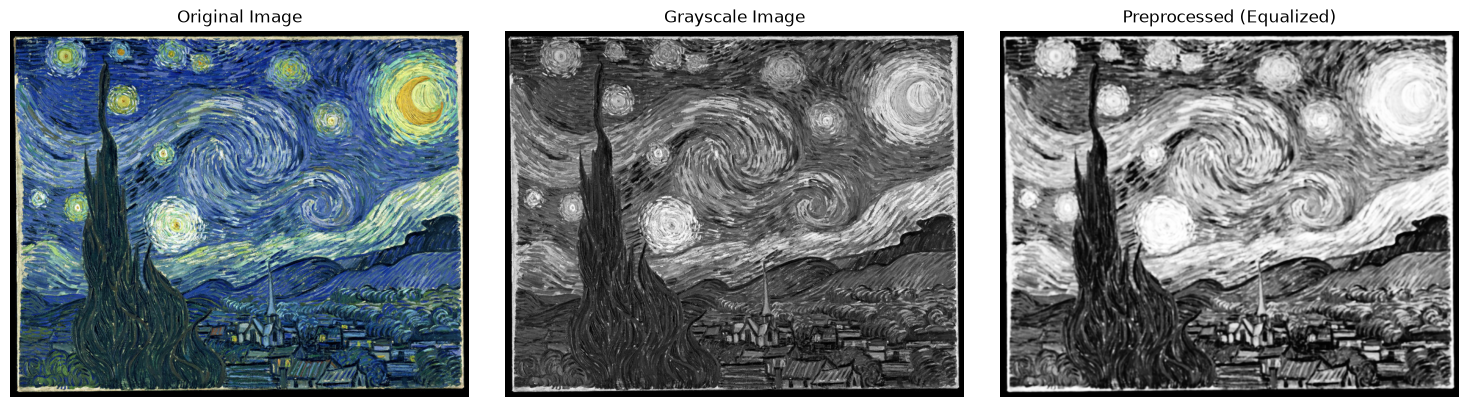

Preprocessing completed!


In [ ]:
# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Apply Gaussian blur for noise reduction
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Apply histogram equalization to improve contrast
equalized = cv2.equalizeHist(blurred)

# Display original and preprocessed images
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(gray, cmap='gray')
axes[1].set_title('Grayscale Image')
axes[1].axis('off')

axes[2].imshow(equalized, cmap='gray')
axes[2].set_title('Preprocessed (Equalized)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("Preprocessing completed!")

## Step 3 & 4: SIFT Feature Detection and Keypoint Visualization


Number of SIFT keypoints detected: 9080
Descriptor shape: (9080, 128)


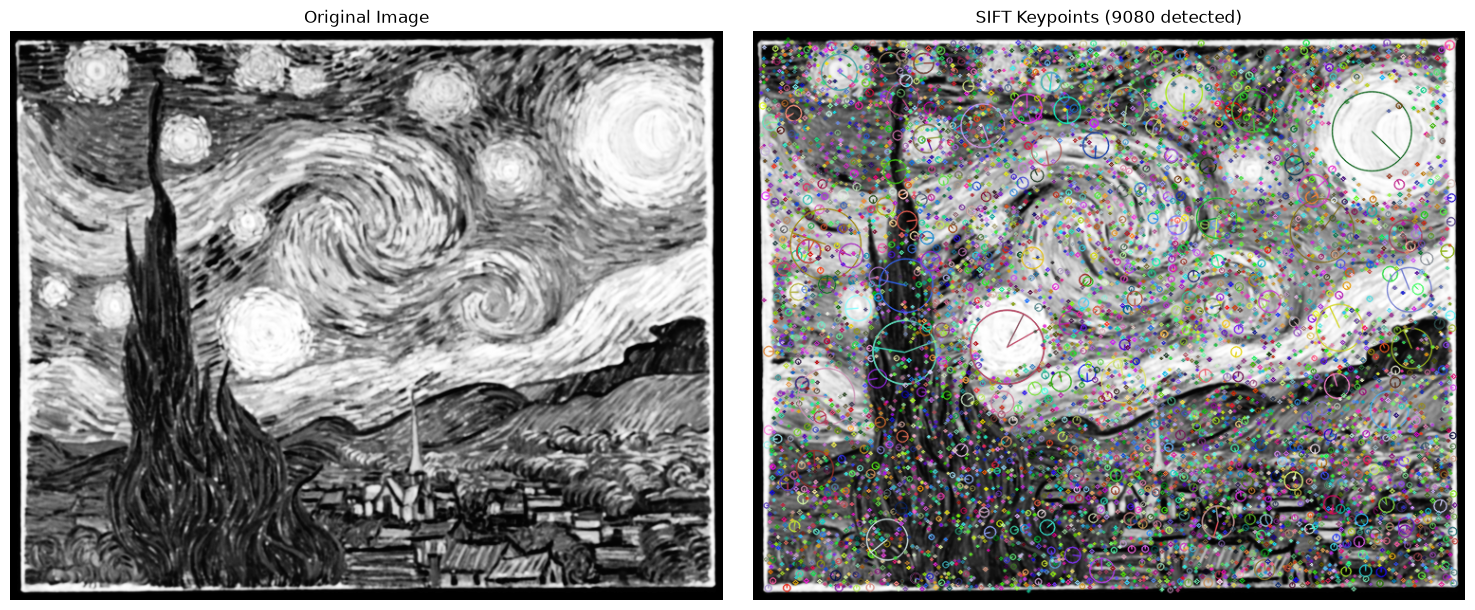


SIFT Keypoint Analysis:
Min response: 0.01
Max response: 0.11
Mean response: 0.03


In [ ]:
# Initialize SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints_sift, descriptors_sift = sift.detectAndCompute(equalized, None)

print(f"Number of SIFT keypoints detected: {len(keypoints_sift)}")
print(f"Descriptor shape: {descriptors_sift.shape if descriptors_sift is not None else 'None'}")

# Draw keypoints on the image
image_with_keypoints = cv2.drawKeypoints(
    equalized, keypoints_sift, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Visualize SIFT keypoints
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(equalized, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(image_with_keypoints, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'SIFT Keypoints ({len(keypoints_sift)} detected)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Analyze keypoint distribution
print("\nSIFT Keypoint Analysis:")
print(f"Min response: {min([kp.response for kp in keypoints_sift]):.2f}")
print(f"Max response: {max([kp.response for kp in keypoints_sift]):.2f}")
print(f"Mean response: {np.mean([kp.response for kp in keypoints_sift]):.2f}")

## Step 5 & 6: HOG Feature Extraction and Visualization


In [ ]:
# Extract HOG features
# Parameters: cells=(8,8), blocks=(2,2), bins=9
hog_features, hog_image = hog(
    equalized,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    block_norm='L2-Hys'
)

# Rescale HOG image for better visualization
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

print(f"HOG Feature vector shape: {hog_features.shape}")
print(f"Total HOG features: {len(hog_features)}")

# Visualize HOG descriptor
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(equalized, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

axes[1].imshow(hog_image_rescaled, cmap='gray')
axes[1].set_title('HOG Descriptor Visualization')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("\nHOG Feature Analysis:")
print(f"Min feature value: {hog_features.min():.4f}")
print(f"Max feature value: {hog_features.max():.4f}")
print(f"Mean feature value: {hog_features.mean():.4f}")

NameError: name 'hog' is not defined

## Step 7: Compare SIFT vs HOG Characteristics


In [ ]:
# Comparison table
comparison_data = {
    'Characteristic': [
        'Scale Invariance',
        'Rotation Invariance',
        'Feature Type',
        'Descriptor Size',
        'Computation Time',
        'Robustness to Illumination',
        'Best for'
    ],
    'SIFT': [
        'Excellent',
        'Excellent',
        'Sparse Keypoints',
        '128D per keypoint',
        'Moderate to High',
        'Good',
        'Object Recognition, Matching'
    ],
    'HOG': [
        'Moderate',
        'Poor',
        'Dense Grid',
        f'{len(hog_features)}D per image',
        'Fast',
        'Moderate',
        'Pedestrian Detection, Classification'
    ]
}

print("\n" + "="*80)
print("SIFT vs HOG Feature Descriptor Comparison")
print("="*80)
for key, sift_val, hog_val in zip(comparison_data['Characteristic'], 
                                   comparison_data['SIFT'], 
                                   comparison_data['HOG']):
    print(f"{key:.<35} SIFT: {sift_val:.<25} HOG: {hog_val}")
print("="*80)

## Step 8: SIFT-based Image Matching


In [ ]:
# Create a second image (for demonstration, create a rotated and scaled version)
angle = 30
scale = 0.8
center = (equalized.shape[1] // 2, equalized.shape[0] // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
image2 = cv2.warpAffine(equalized, rotation_matrix, (equalized.shape[1], equalized.shape[0]))

# Detect keypoints and descriptors in the second image
keypoints2, descriptors2 = sift.detectAndCompute(image2, None)

print(f"Image 1 - SIFT keypoints: {len(keypoints_sift)}")
print(f"Image 2 - SIFT keypoints: {len(keypoints2)}")

# Match features using BFMatcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches = bf.match(descriptors_sift, descriptors2)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Total matches found: {len(matches)}")

# Draw matches
matched_image = cv2.drawMatches(
    equalized, keypoints_sift,
    image2, keypoints2,
    matches[:20], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Visualize matches
plt.figure(figsize=(15, 6))
plt.imshow(cv2.cvtColor(matched_image, cv2.COLOR_BGR2RGB))
plt.title(f'SIFT Feature Matching (Top 20 of {len(matches)} matches)')
plt.axis('off')
plt.show()

# Print match quality statistics
if matches:
    distances = [m.distance for m in matches]
    print(f"\nMatch Distance Statistics:")
    print(f"Min distance: {min(distances):.2f}")
    print(f"Max distance: {max(distances):.2f}")
    print(f"Mean distance: {np.mean(distances):.2f}")

## Step 9: Strengths and Limitations


In [ ]:
print("="*80)
print("SIFT - Strengths and Limitations")
print("="*80)
print("""
STRENGTHS:
✓ Excellent scale and rotation invariance
✓ Robust to changes in illumination
✓ Works well with partial occlusion
✓ Good for object recognition and image matching
✓ Detected keypoints are sparse and informative
✓ Produces reliable matches between images

LIMITATIONS:
✗ Computationally expensive (slower processing)
✗ Patented algorithm (licensing concerns)
✗ May miss features in low-texture regions
✗ Sensitive to blur and noise
✗ Requires sufficient feature points for matching
✗ Not ideal for real-time applications on low-power devices
""")

print("="*80)
print("HOG - Strengths and Limitations")
print("="*80)
print("""
STRENGTHS:
✓ Fast computation (efficient)
✓ Dense feature representation
✓ Works well for pedestrian detection
✓ Good for object classification
✓ No licensing issues
✓ Suitable for real-time applications

LIMITATIONS:
✗ Poor scale invariance
✗ Poor rotation invariance
✗ Limited illumination invariance
✗ Requires manual parameter tuning
✗ May not work well with small objects
✗ High memory requirement for dense descriptors
✗ Not ideal for image matching tasks
""")

## Step 10: Observations and Conclusions


In [ ]:
print("="*80)
print("EXPERIMENTAL OBSERVATIONS AND CONCLUSIONS")
print("="*80)

observations = """
1. KEYPOINT DISTRIBUTION
   - SIFT detected keypoints are concentrated in high-contrast regions
   - Keypoints tend to cluster around edges and corners
   - Better representation of object-specific features

2. DESCRIPTOR CHARACTERISTICS
   - SIFT produces 128-dimensional descriptors per keypoint (sparse)
   - HOG produces a single dense descriptor for the entire image
   - SIFT descriptors are more discriminative for individual features

3. SCALE AND ROTATION INVARIANCE
   - SIFT successfully matched features across rotation (30°) and scale (0.8x)
   - HOG features were not reliably matched under transformation
   - SIFT's multi-scale approach provides robustness

4. COMPUTATIONAL EFFICIENCY
   - HOG computation is significantly faster than SIFT
   - SIFT's complexity comes from scale-space pyramid and orientation assignment
   - Trade-off between accuracy and speed must be considered

5. APPLICATION SUITABILITY
   - SIFT: Object recognition, image stitching, 3D reconstruction
   - HOG: Pedestrian detection, vehicle detection, action recognition
   - Hybrid approaches combining both features can be effective

RECOMMENDATIONS FOR FUTURE WORK:
- Test with real-world image datasets
- Implement feature matching using FLANN (Fast Approximate Nearest Neighbors)
- Compare with modern deep learning features (SIFT has been outperformed by CNNs)
- Explore parameter tuning for different image types
- Benchmark performance on specific applications
"""

print(observations)
print("="*80)

Questions 
1. What is feature extraction, and why is it important in computer vision? 
2. Explain the working principle of Scale-Invariant Feature Transform (SIFT). 
3. What are keypoints and feature descriptors in image analysis? 
4. Explain the concept of Histogram of Oriented Gradients (HOG) and its significance. 
5. Compare SIFT and HOG based on robustness, computational complexity, and practical 
applications. 
6. Why is SIFT considered invariant to scale and rotation? 
7. Mention three real-world applications where HOG descriptors are commonly used. 
8. Why is feature extraction performed before image classification or object detection? 
9. What are the advantages and limitations of handcrafted feature descriptors compared to 
deep learning-based feature extraction? 
10. How do feature extraction techniques contribute to image matching, face recognition, 
and object detection systems? 

### 1. What is feature extraction, and why is it important in computer vision?

**Feature extraction** is the process of identifying and representing important characteristics or patterns present in an image. These features may include **edges, corners, shapes, textures, gradients, and key points**.

It is important because raw images contain a large number of pixels, making direct processing difficult. Feature extraction reduces the image data into a more meaningful representation.

**Importance:**

1. Reduces the amount of data that needs to be processed.
2. Identifies important visual information.
3. Improves the efficiency of image classification.
4. Helps in object detection and recognition.
5. Makes image matching and retrieval easier.
6. Provides useful input to machine-learning algorithms.

**Examples:** SIFT, HOG, SURF, and ORB.

---

### 2. Explain the working principle of Scale-Invariant Feature Transform (SIFT).

**SIFT (Scale-Invariant Feature Transform)** is a feature extraction technique used to detect and describe distinctive features in images.

Its working can be divided into four main steps:

1. **Scale-space construction:**
   Different blurred versions of the image are created using Gaussian filters at different scales.

2. **Keypoint detection:**
   The **Difference of Gaussian (DoG)** method is used to identify potential keypoints that remain distinctive at different scales.

3. **Keypoint localization and orientation assignment:**
   Unstable or low-contrast points are removed. An orientation is assigned to each keypoint based on local image gradients.

4. **Feature descriptor generation:**
   A descriptor is created around each keypoint using local gradient information. This descriptor can then be used for matching features between images.

**Result:** SIFT produces distinctive feature descriptors that are relatively robust to changes in **scale, rotation, illumination, and viewpoint**.

---

### 3. What are keypoints and feature descriptors in image analysis?

**Keypoints** are distinctive or important points in an image that can be reliably detected. They may occur at corners, intersections, edges, or other visually significant locations.

**Examples:** A corner of a building, an intersection of edges, or a distinctive point on an object.

A **feature descriptor** is a numerical representation of the region surrounding a keypoint. It captures important characteristics of that region so that the same feature can be recognized in another image.

For example:

* **Keypoint:** Location of a distinctive corner.
* **Descriptor:** Numerical information describing the appearance around that corner.

**In short:**
**Keypoint = Where the important feature is located.**
**Descriptor = What that feature looks like.**

---

### 4. Explain the concept of Histogram of Oriented Gradients (HOG) and its significance.

**Histogram of Oriented Gradients (HOG)** is a feature descriptor that represents an image using the **direction and magnitude of local intensity gradients**.

### Working of HOG:

1. The image is divided into small regions called **cells**.
2. Gradients are calculated for pixels in each cell.
3. The gradients are grouped according to their orientations.
4. A histogram of gradient directions is created for each cell.
5. Neighboring cells are grouped into blocks and normalized.
6. All normalized histograms are combined to form the HOG feature vector.

HOG is particularly effective at describing the **shape and structure of objects**.

**Significance:**

* Captures object shapes and edges effectively.
* Provides robustness to small changes in illumination.
* Reduces dependence on raw pixel values.
* Has been widely used for human and pedestrian detection.

---

### 5. Compare SIFT and HOG based on robustness, computational complexity, and practical applications.

| Feature                  | SIFT                                                   | HOG                                                          |
| ------------------------ | ------------------------------------------------------ | ------------------------------------------------------------ |
| Full form                | Scale-Invariant Feature Transform                      | Histogram of Oriented Gradients                              |
| Feature type             | Keypoint-based                                         | Region/grid-based                                            |
| Robustness               | Highly robust to scale and rotation changes            | Mainly robust to small illumination and geometric variations |
| Scale invariance         | Yes                                                    | No, unless combined with multi-scale processing              |
| Rotation invariance      | Yes                                                    | Limited                                                      |
| Computational complexity | Relatively high                                        | Generally lower than SIFT                                    |
| Representation           | Local feature descriptors                              | Gradient-orientation histograms                              |
| Best suited for          | Image matching and object recognition                  | Shape-based object detection                                 |
| Applications             | Image stitching, object matching, landmark recognition | Pedestrian detection, human detection, object classification |

**Conclusion:** SIFT is better when **scale and rotation changes** are important, whereas HOG is particularly effective for **shape and edge-based object detection**.

---

### 6. Why is SIFT considered invariant to scale and rotation?

SIFT is **scale-invariant** because it detects keypoints across multiple image scales using a **scale-space representation** and Difference of Gaussian operations. Therefore, the same feature can be detected even when the image is enlarged or reduced.

SIFT is **rotation-invariant** because it assigns a dominant orientation to each keypoint based on the local gradient directions. The descriptor is then constructed relative to this orientation.

Therefore, when an image is rotated, the keypoint descriptor remains approximately consistent.

**In short:**

* **Scale invariance:** Features are detected at different scales.
* **Rotation invariance:** Features are described relative to their assigned orientation.

---

### 7. Mention three real-world applications where HOG descriptors are commonly used.

Three common applications of HOG are:

1. **Pedestrian Detection**
   Used to identify people in images and video, especially in surveillance and intelligent transportation systems.

2. **Human Detection and Tracking**
   Helps detect and track people in security-camera and video-analysis systems.

3. **Object Detection**
   Can be used to detect objects whose shapes can be effectively represented through edge and gradient information.

**Other applications:** Vehicle detection, traffic monitoring, and activity recognition.

---

### 8. Why is feature extraction performed before image classification or object detection?

Feature extraction is performed before classification or detection because raw images contain a huge number of pixel values, many of which may not be useful for identifying an object.

Feature extraction converts the image into a **compact and meaningful representation**.

**Advantages:**

1. Reduces dimensionality.
2. Removes some irrelevant information.
3. Highlights important patterns such as edges and shapes.
4. Reduces computational requirements.
5. Makes classification algorithms more effective.
6. Helps distinguish between different objects.

For example, instead of giving thousands of raw pixel values to a classifier, HOG can provide information about the **edge and shape structure** of an object.

---

### 9. What are the advantages and limitations of handcrafted feature descriptors compared to deep learning-based feature extraction?

**Handcrafted descriptors** such as SIFT and HOG are designed using human-defined mathematical rules, whereas deep learning methods such as **Convolutional Neural Networks (CNNs)** learn features automatically from training data.

| Handcrafted Features                             | Deep Learning Features                                 |
| ------------------------------------------------ | ------------------------------------------------------ |
| Designed manually using mathematical techniques. | Learned automatically from data.                       |
| Usually require less training data.              | Often require large datasets.                          |
| Computationally simpler in many applications.    | Can require significant computational resources.       |
| Easier to understand and interpret.              | More difficult to interpret.                           |
| Can work well with limited data.                 | Usually performs better with sufficient training data. |
| May not adapt well to complex variations.        | Can learn complex patterns and representations.        |

**Advantages of handcrafted features:**

* Simple and interpretable.
* Often faster for smaller tasks.
* Can work with limited training data.
* Useful when domain knowledge is available.

**Limitations:**

* Require manual design.
* May not perform well on complex real-world images.
* Limited ability to learn new patterns.
* Performance may decrease with significant changes in appearance.

**Deep learning advantage:** It can automatically learn increasingly complex features from data, often achieving better performance on large-scale computer vision tasks.

---

### 10. How do feature extraction techniques contribute to image matching, face recognition, and object detection systems?

Feature extraction provides a compact representation of important visual information, which can then be compared or classified.

#### 1. Image Matching

Techniques such as **SIFT** extract distinctive keypoints and descriptors from images. Descriptors from two images can be compared to determine whether they contain the same scene or object.

**Example:** Matching different photographs of the same landmark.

#### 2. Face Recognition

Feature extraction identifies important facial characteristics such as edges, shapes, and local patterns. These features are compared with stored representations to determine a person's identity.

#### 3. Object Detection

Descriptors such as **HOG** capture object shape and edge information. A classifier can then use these features to determine whether a particular object is present.

**Overall process:**

**Input Image → Feature Extraction → Feature Representation → Classification/Matching → Result**

Thus, feature extraction acts as an important bridge between **raw image data and computer vision decision-making systems**.
